#Stage 2: Multi-class Image Classification (EfficientNetB0)


**Classifications:** Healthy, Magnesium Deficiency, Manganese Deficiency, Potassium Deficiency.

**Outline**
1. Colab setup (GPU, Google Drive, dataset location)
2. Data pre-processing (load, resize, normalize, encode, split)
3. EfficientNetB0 model: build and train
4. Evaluation (accuracy, confusion matrix)
5. Prediction on an unseen image

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/Colab Notebooks/Stage2') # Getting dataset from google-drive
print("Current folder:", os.getcwd())
print("Contents:", os.listdir('.'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Current folder: /content/drive/MyDrive/Colab Notebooks/Stage2
Contents: ['dataset', 'unseen_mang.png']


---
## Data Pre-Processing
### Imports and reading the dataset folder
Lists the class folders found inside `dataset` and prints how many classes there are.

In [6]:
## Data Pre Processing

import numpy as np
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Getting images and labels from the dataset folder
dataset_path = os.listdir('dataset')
print()
print("=" * 50)
print("Datasets:")
print (dataset_path)  #what kinds of classes are in this dataset
print("Types of classes labels found: ", len(dataset_path))
print("=" * 50)


Datasets:
['Potassium Deficiency', 'Manganese Deficiency', 'Healthy sample', 'Magnesium Deficiency']
Types of classes labels found:  4


### Build a DataFrame of labels and image paths
Walks through every class folder and records each image's label and path, then shows how many images each class has (useful to spot class imbalance).

In [7]:
class_labels = []
for item in dataset_path:
 # Get all the file names
 all_classes = os.listdir('dataset' + '/' +item)
 # print(all_classes)
 # Add them to the list
 for room in all_classes:
    class_labels.append((item, str('dataset_path' + '/' +item) + '/' + room))
    #print(class_labels[:5])

# Build a dataframe
df = pd.DataFrame(data=class_labels, columns=['Labels', 'image'])
print()
print("=" * 50)
print("Putting everything together:")
print(df.head())
print(df.tail())
print("=" * 50)

# Let's check how many samples for each category are present
print()
print("=" * 50)
print("Details of the list:")
print("Total number of images in the dataset: ", len(df))
label_count = df['Labels'].value_counts()
print(label_count)
print("=" * 50)


Putting everything together:
                 Labels                                           image
0  Potassium Deficiency  dataset_path/Potassium Deficiency/M9 (133).png
1  Potassium Deficiency  dataset_path/Potassium Deficiency/M9 (129).png
2  Potassium Deficiency   dataset_path/Potassium Deficiency/M9 (11).png
3  Potassium Deficiency  dataset_path/Potassium Deficiency/M9 (131).png
4  Potassium Deficiency  dataset_path/Potassium Deficiency/M9 (107).png
                    Labels                                           image
2193  Magnesium Deficiency  dataset_path/Magnesium Deficiency/M6 (553).png
2194  Magnesium Deficiency  dataset_path/Magnesium Deficiency/M6 (528).png
2195  Magnesium Deficiency    dataset_path/Magnesium Deficiency/M6 (6).png
2196  Magnesium Deficiency   dataset_path/Magnesium Deficiency/M6 (75).png
2197  Magnesium Deficiency    dataset_path/Magnesium Deficiency/M6 (8).png

Details of the list:
Total number of images in the dataset:  2198
Labels
Potassium Defi

### Load, resize and normalize the images
Each image is read with OpenCV, resized to **224×224**, and stored in a list. Pixel values are then scaled to the 0–1 range as `float32`.

In [8]:
import cv2
path = 'dataset/'
dataset_path = os.listdir('dataset')
im_size = 224
images = []
labels = []
for i in dataset_path:
    data_path = path + str(i)
    filenames = [i for i in os.listdir(data_path) ]
    for f in filenames:
        img = cv2.imread(data_path + '/' + f)
        img = cv2.resize(img, (im_size, im_size))
        images.append(img)
        labels.append(i)


#This model takes input images of shape (224, 224, 3), and the input data should range [0, 255].
images = np.array(images)
images = images.astype('float32') / 255.0
print()
print("Images shape: ")
images.shape


Images shape: 


(2198, 224, 224, 3)

### Encode the labels
Class names (text) are converted to integers with `LabelEncoder`, then to one-hot vectors with `OneHotEncoder` (needed for `categorical_crossentropy`).

In [9]:
print()
print("=" * 50)
print("One Hot Encoding the labels")
from sklearn.preprocessing import LabelEncoder , OneHotEncoder
y=df['Labels'].values
print(y)
y_labelencoder = LabelEncoder ()
y = y_labelencoder.fit_transform (y)
print (y)


y=y.reshape(-1,1)
from sklearn.compose import ColumnTransformer
ct = ColumnTransformer([('my_ohe', OneHotEncoder(), [0])], remainder='passthrough')
Y = ct.fit_transform(y).toarray()
print(Y[:5])
print(Y[35:])
print("=" * 50)


One Hot Encoding the labels
['Potassium Deficiency' 'Potassium Deficiency' 'Potassium Deficiency' ...
 'Magnesium Deficiency' 'Magnesium Deficiency' 'Magnesium Deficiency']
[3 3 3 ... 1 1 1]
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 ...
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]]


### Shuffle and split into train / test
Shuffles the data, then keeps **80% for training** and **20% for testing**.

In [10]:
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
images, Y = shuffle(images, Y, random_state=1)
train_x, test_x, train_y, test_y = train_test_split(images, Y, test_size=0.2, random_state=415)
#inpect the shape of the training and testing.
print()
print("=" * 50)
print("Shape of the training and testing data")
print(train_x.shape)
print(train_y.shape)
print(test_x.shape)
print("=" * 50)


Shape of the training and testing data
(1758, 224, 224, 3)
(1758, 4)
(440, 224, 224, 3)


##  EfficientNetB0 Model
###  Build, compile and train
EfficientNetB0 is built **from scratch (no pretrained weights)** with 4 output classes, compiled with Adam and categorical cross-entropy.

In [11]:
## EfficientNetB0 model for multi-class classification

from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
NUM_CLASSES = 4
IMG_SIZE = 224
size = (IMG_SIZE, IMG_SIZE)
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
# Using model without transfer learning
outputs = EfficientNetB0(include_top=True, weights=None, classes=NUM_CLASSES)(inputs)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"] )
model.summary()
hist = model.fit(train_x, train_y, epochs=50, verbose=1)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4)              │     4,054,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 4,012,672 (15.31 MB)

 Non-trainable params: 42,023 (164.16 KB)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.3987 - loss: 2.6975
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 17s 117ms/step - accuracy: 0.5256 - loss: 1.6267
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.6109 - loss: 1.4189
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.6547 - loss: 0.9912
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.6843 - loss: 1.1292
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.7281 - loss: 0.9207
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.7531 - loss: 0.7519
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - accuracy: 0.7298 - loss: 0.8336
Epoch 9/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.7935 - loss: 0.6349
Epoch 10/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.8532 - loss: 0.4820
Epoch 11/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.8424 - loss: 0.5826
Epoch 12/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step

Training curve
Plots the training accuracy for each epoch.

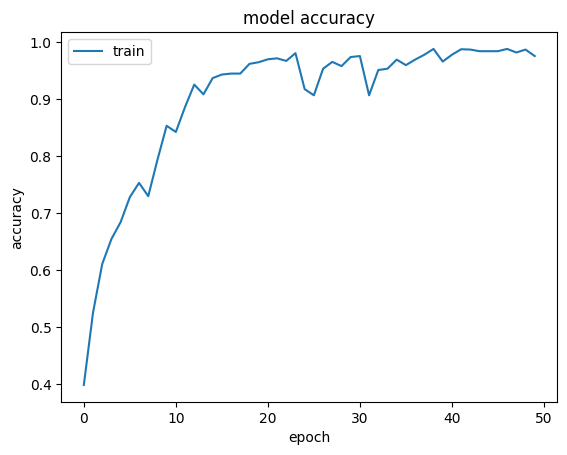

In [12]:
import matplotlib.pyplot as plt
def plot_hist(hist):
    plt.plot(hist.history["accuracy"])
    #plt.plot(hist.history["val_accuracy"])
    plt.title("model accuracy")
    plt.ylabel("accuracy")
    plt.xlabel("epoch")
    plt.legend(["train", "validation"], loc="upper left")
    plt.show()
plot_hist(hist)

## Evaluation
### Test loss and accuracy
Evaluates the trained model on the 20% test split that it has never seen.

In [13]:
print()
print("=" * 50)
preds = model.evaluate(test_x, test_y)
print ("Loss = " + str(preds[0]))
print ("Test Accuracy = " + str(preds[1]))
print("=" * 50)


14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 691ms/step - accuracy: 0.7068 - loss: 1.2478
Loss = 1.2477900981903076
Test Accuracy = 0.706818163394928


### Confusion matrix
Shows, for the test set, which classes are predicted correctly and which ones get confused with each other.

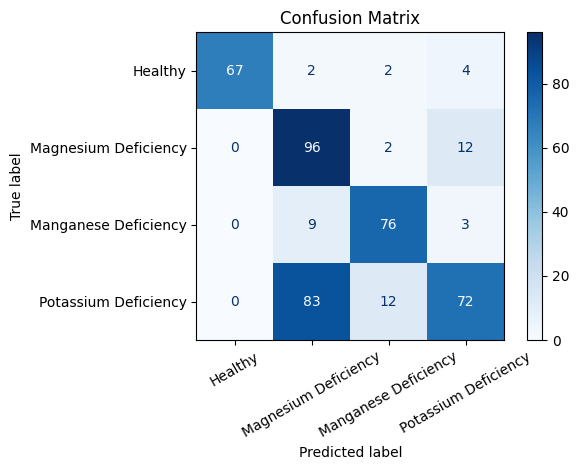

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["Healthy", "Magnesium Deficiency", "Manganese Deficiency", "Potassium Deficiency"]

y_pred = np.argmax(model.predict(test_x, verbose=0), axis=1)
y_true = np.argmax(test_y, axis=1)

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=30)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Precision, Recall and Accuracy
Calculates the performance metrics directly from the confusion matrix above:
- **Precision**: of all trees predicted as a given class, how many really belong to it.
- **Recall**: of all trees that truly belong to a given class, how many the model found.
- **Accuracy**: overall share of correct predictions across all classes.

The **macro average** is the simple average across the 4 classes, so each class counts equally.

In [15]:
# Precision, Recall and Accuracy computed from the confusion matrix (cm)
# Rows of cm = true class, columns of cm = predicted class

TP = np.diag(cm)                      # correct predictions per class
FP = cm.sum(axis=0) - TP              # predicted as this class, but actually another class
FN = cm.sum(axis=1) - TP              # actually this class, but predicted as another class

precision = TP / (TP + FP + 1e-10)    # of all predicted as X, how many were really X
recall    = TP / (TP + FN + 1e-10)    # of all real X, how many were found
accuracy  = TP.sum() / cm.sum()       # overall correct predictions / total predictions

print()
print("=" * 50)
print(f"{'Class':<24}{'Precision':>10}{'Recall':>10}")
print("-" * 44)
for name, p, r in zip(class_names, precision, recall):
    print(f"{name:<24}{p * 100:>9.1f}%{r * 100:>9.1f}%")
print("-" * 44)
print(f"{'Macro average':<24}{precision.mean() * 100:>9.1f}%{recall.mean() * 100:>9.1f}%")
print(f"\nOverall Accuracy: {accuracy * 100:.2f}%")
print("=" * 50)


Class                    Precision    Recall
--------------------------------------------
Healthy                     100.0%     89.3%
Magnesium Deficiency         50.5%     87.3%
Manganese Deficiency         82.6%     86.4%
Potassium Deficiency         79.1%     43.1%
--------------------------------------------
Macro average                78.1%     76.5%

Overall Accuracy: 70.68%


### Load and preview an unseen image
Reads `unseen.png`, resizes it to 224×224 and prepares it for the model. Make sure `unseen.png` is in your Drive project folder.

Input image shape: (1, 224, 224, 3)


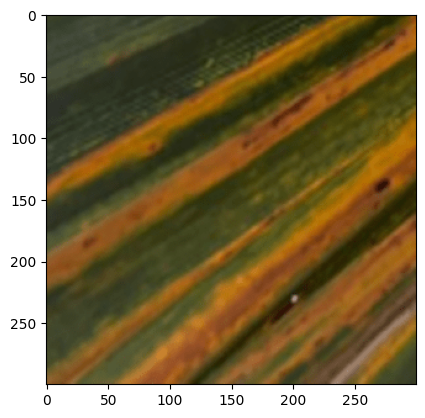

In [18]:
from matplotlib.pyplot import imread
from matplotlib.pyplot import imshow
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.imagenet_utils import decode_predictions
from tensorflow.keras.applications.imagenet_utils import preprocess_input
img_path = '/content/drive/MyDrive/Colab Notebooks/Stage2/unseen_mang.png'
#img = image.load_img(img_path, target_size=(224, 224))
#x = img.img_to_array(img)
img = cv2.imread(img_path)
img = cv2.resize(img, (224, 224))
x = np.expand_dims(img, axis=0)
x = preprocess_input(x)
print('Input image shape:', x.shape)
my_image = imread(img_path)
imshow(my_image)

---
## Prediction on the Unseen Image
Prints the probability (%) for each of the 4 classes and the final predicted class.

In [19]:
print()
print("=" * 50)
print("Prediction for unseen image:")
preds=model.predict(x)
print(preds)     # probabilities for being in each of the 4 classes
preds = model.predict(x)[0]
classes = ["Healthy", "Magnesium Deficiency", "Manganese Deficiency", "Potassium Deficiency"]
print("\nPrediction for unseen image:")
for name, p in zip(classes, preds):
    print(f"  {name:<22} {p * 100:5.1f}%")
print(f"\nPredicted: {classes[preds.argmax()]}")
print("=" * 50)


Prediction for unseen image:
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
[[1. 0. 0. 0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

Prediction for unseen image:
  Healthy                100.0%
  Magnesium Deficiency     0.0%
  Manganese Deficiency     0.0%
  Potassium Deficiency     0.0%

Predicted: Healthy
